# Step 44 — Compare daily hypocenter-source coverage

This diagnostic compares record counts in the two **input origin indexes**, not preferred events from step 43. The sources overlap, so do not sum their counts as independent earthquakes. Daily count differences can reflect missing records, revised solutions, duplicate solutions, parser failures and unresolved time conventions.

The loader parses `origin_time`, excludes unparseable/missing times from the plot and counts rows (not deduplicated physical events). Timezone representation does not validate historical UTC timing. In particular, unresolved annotated origins are absent from daily bins; inspect the ingestion audit for their number.

The plot uses separate source panels, one-day-wide bars and a full calendar shared across sources, so missing days are visible without stacking overlapping catalogues. Its companion CSV contains zero-filled daily source counts. The PNG and CSV replace matching outputs under the configured external QC directory. This is a coverage figure, not proof of catalogue completeness.

## 1. Configuration

Review source paths, selected PINAALL variant and output paths before running. Configuration does not execute the workflow.

In [1]:
from pathlib import Path
import sys
from IPython.display import display

# Find the adjacent local package whether Jupyter starts here or in the project root.
_candidates = [Path.cwd(), Path.cwd() / '10_conversion', *Path.cwd().parents]
PIPELINE_DIR = next((p for p in _candidates if (p / 'pinatubo_steps').is_dir()), None)
if PIPELINE_DIR is None:
    raise FileNotFoundError('Open this notebook from the pipeline folder or project root.')
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))
from pinatubo_steps.config import pipeline_paths

CONFIG_FILE = None  # Default: conversion_config.json; or set an explicit JSON path.
P = pipeline_paths(config_file=CONFIG_FILE)
DATA_TOP = Path(P['DATA_TOP'])
print('Configuration:', P['CONFIG_FILE'])
print('External outputs:', P['OUTPUT_ROOT'])

SETTINGS = dict(
    hypo40=P['SUMMARY_FILE_40_INDEX'],
    hypo41=P['SUMMARY_FILE_41_INDEX'],
    out=f"{P['HYPO_QC_DIR']}/44_hypocenters_per_day.png",
)
display(SETTINGS)

Configuration: /Users/thompsong/Developer/Pinatubo1991SeismicData/10_conversion/conversion_config.json
External outputs: /Users/thompsong/work/Pinatubo1991Processing/converted


{'hypo40': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/40_summary_file_index.csv',
 'hypo41': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/41_summary_file_index.csv',
 'out': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step44_hypo71_diagnostics/44_hypocenters_per_day.png'}

## 2. Implementation

The complete step-specific workflow is defined below. Definitions alone do not read sources or write products.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


def load_daily_counts(csv: Path, label: str) -> pd.DataFrame:
    df = pd.read_csv(csv)

    if "origin_time" not in df.columns:
        raise ValueError(f"{csv} missing origin_time column")

    df["origin_time"] = pd.to_datetime(
        df["origin_time"], format="mixed", utc=True, errors="coerce"
    )
    df = df.dropna(subset=["origin_time"])

    df["date"] = df["origin_time"].dt.floor("D")

    daily = (
        df.groupby("date")
        .size()
        .rename("n_hypocenters")
        .reset_index()
    )

    daily["source"] = label
    return daily


def run(
    *,
    hypo40,
    hypo41,
    out
):
    """Run this Pinatubo step with explicit notebook arguments. Return tables and results for inspection."""
    from types import SimpleNamespace
    args = SimpleNamespace(
        hypo40=hypo40,
        hypo41=hypo41,
        out=out,
    )

    df40 = load_daily_counts(Path(args.hypo40), "HYPO71 (Pinatubo_all.sum)")
    df41 = load_daily_counts(Path(args.hypo41), "PINAALL.DAT")

    daily = pd.concat([df40, df41], ignore_index=True)

    if daily.empty:
        raise ValueError('No resolved origin times available for plotting.')
    import matplotlib.dates as mdates
    days = pd.date_range(daily['date'].min(), daily['date'].max(), freq='D', name='date')
    counts = daily.pivot(index='date', columns='source', values='n_hypocenters').reindex(days).fillna(0).astype(int)
    fig, axes = plt.subplots(len(counts.columns), 1, sharex=True, sharey=True,
                             figsize=(12, 6), squeeze=False)
    for ax, source in zip(axes[:, 0], counts.columns):
        ax.bar(days, counts[source], width=1, align='edge', linewidth=0)
        ax.set(title=source, ylabel='Origin records/day')
        ax.grid(axis='y', alpha=0.2)
        ax.set_axisbelow(True)
    locator = mdates.AutoDateLocator(minticks=5, maxticks=12)
    axes[-1, 0].xaxis.set_major_locator(locator)
    axes[-1, 0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    axes[-1, 0].set_xlim(days[0], days[-1] + pd.Timedelta(days=1))
    axes[-1, 0].set_xlabel('Recorded origin date (UTC convention not independently verified)')
    fig.tight_layout()
    out = Path(args.out)
    out.parent.mkdir(parents=True, exist_ok=True)
    counts.to_csv(out.with_suffix('.csv'))
    fig.savefig(out, dpi=180)
    plt.close(fig)

    print("\nHypocenter daily plot written to:")
    print(out)
    return {k: v for k, v in locals().items() if (k.startswith("df") or k.startswith("catalog") or k.endswith("_rows") or k in ("events", "annotations", "errors", "stats", "diag", "merged", "suppressed", "matches", "rows", "unparsed"))}

## 3. Execute when ready

This cell reads configured inputs and replaces configured outputs. Inspect summaries and diagnostic tables after the run.

In [3]:
result = run(**SETTINGS)


Hypocenter daily plot written to:
/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step44_hypo71_diagnostics/44_hypocenters_per_day.png


In [4]:
# Preview returned tables and summary objects without reloading output files.
for name, value in result.items():
    print(name)
    display(value.head() if hasattr(value, 'head') else
            value[:5] if isinstance(value, list) else value)


df40


,date,n_hypocenters,source
0,1991-05-07 00:00:00+00:00,2,HYPO71 (Pinatubo_all.sum)
1,1991-05-08 00:00:00+00:00,5,HYPO71 (Pinatubo_all.sum)
2,1991-05-09 00:00:00+00:00,5,HYPO71 (Pinatubo_all.sum)
3,1991-05-10 00:00:00+00:00,2,HYPO71 (Pinatubo_all.sum)
4,1991-05-11 00:00:00+00:00,2,HYPO71 (Pinatubo_all.sum)


df41


,date,n_hypocenters,source
0,1991-05-10 00:00:00+00:00,2,PINAALL.DAT
1,1991-05-11 00:00:00+00:00,1,PINAALL.DAT
2,1991-05-12 00:00:00+00:00,1,PINAALL.DAT
3,1991-05-16 00:00:00+00:00,2,PINAALL.DAT
4,1991-05-20 00:00:00+00:00,5,PINAALL.DAT


1 saved PNG figures; showing up to four.
/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step44_hypo71_diagnostics/44_hypocenters_per_day.png


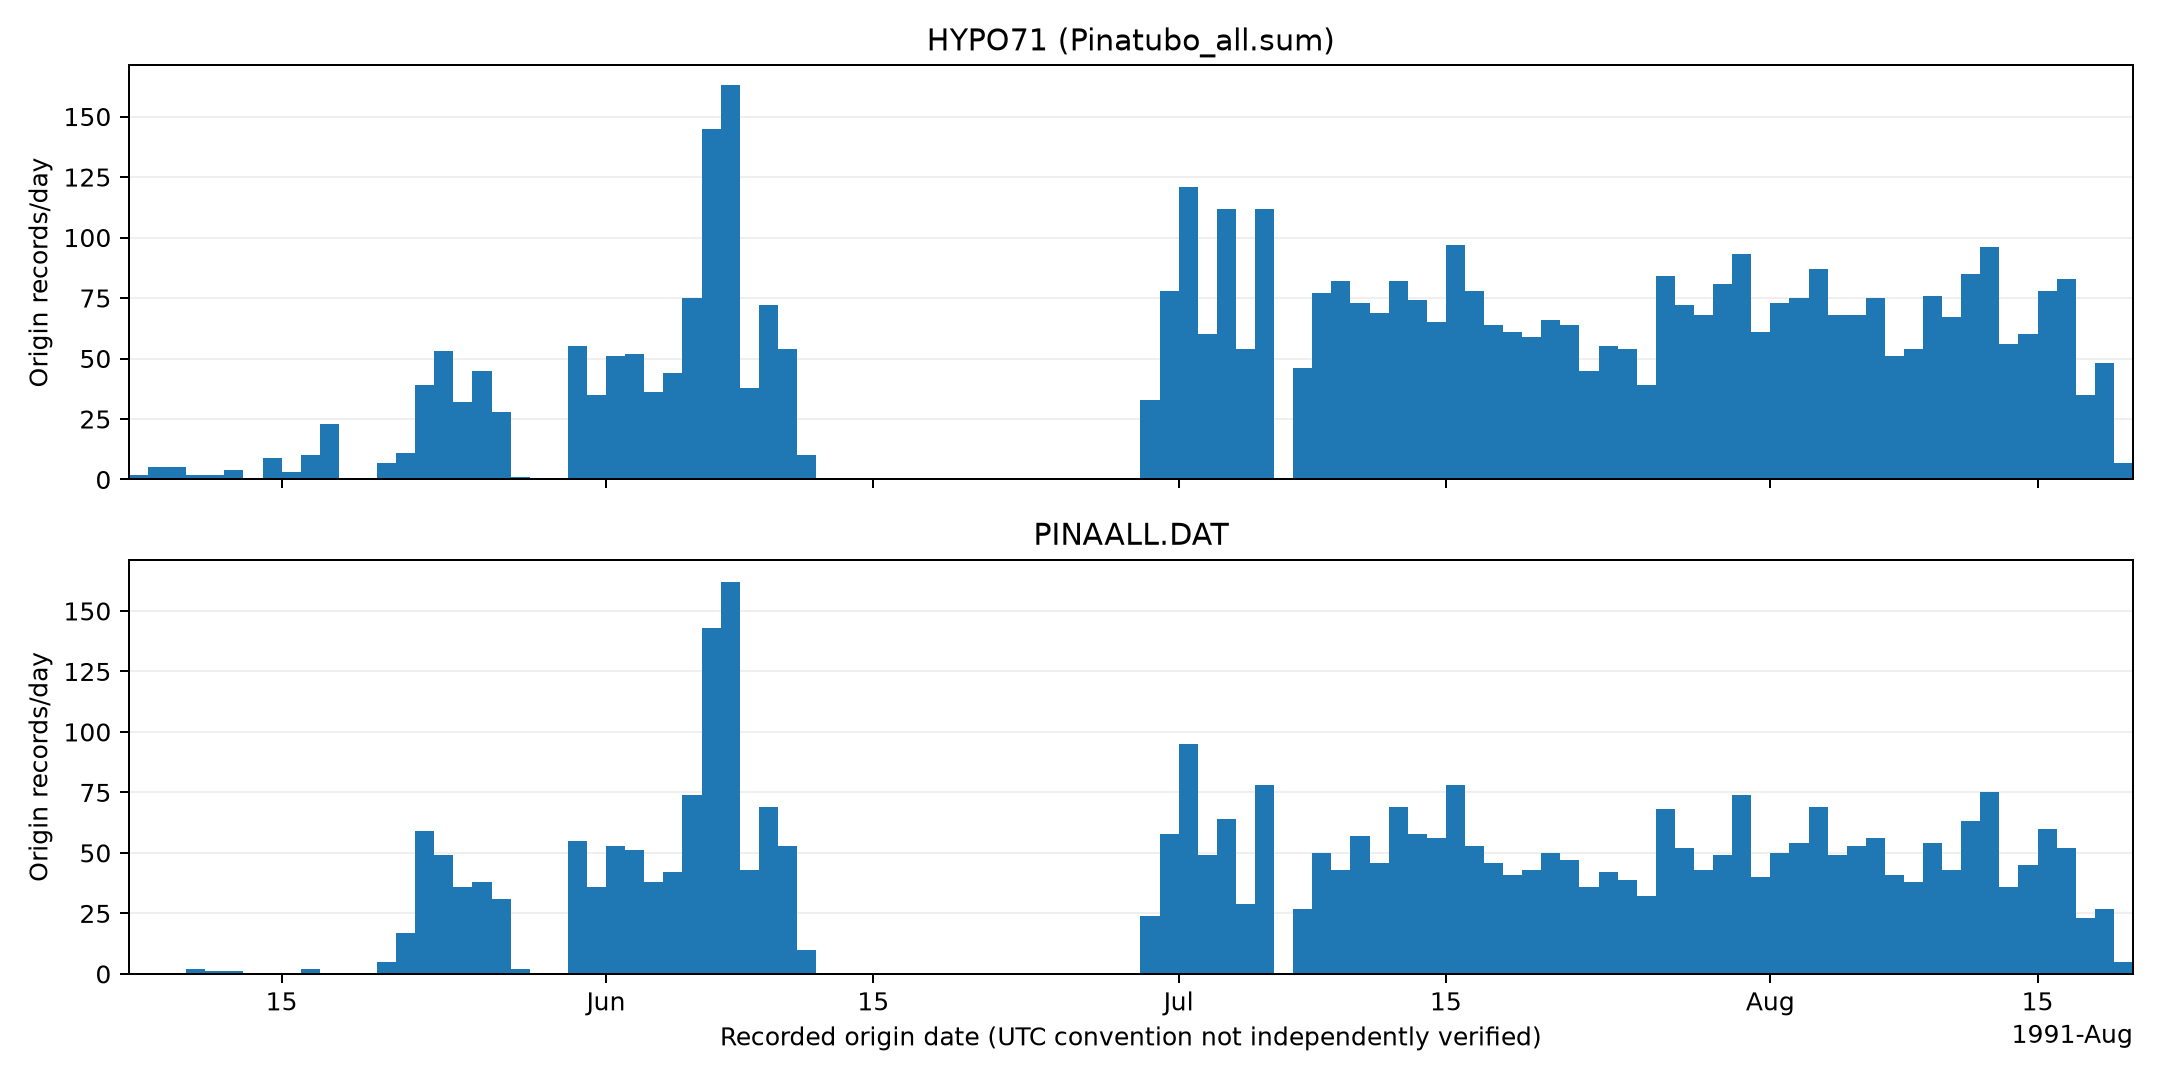

In [5]:
from IPython.display import Image

# Show saved diagnostics inline; all figures remain in the configured folder.
plot_roots = [Path(SETTINGS[k]) for k in ('outdir', 'out_dir', 'out')
              if k in SETTINGS and SETTINGS[k] is not None]
plots = sorted({p for root in plot_roots
                for p in ([root] if root.suffix.lower() == '.png'
                          else root.rglob('*.png')) if p.is_file()})
print(f'{len(plots)} saved PNG figures; showing up to four.')
for plot in plots[:4]:
    print(plot)
    display(Image(filename=str(plot)))
